# Buổi 9: Học sâu

Cài đặt thư viện tensorflow
```bash
pip install tensorflow
```

In [9]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)

[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for tensorflow


## 1. Khai báo thư viện

In [3]:
import numpy as np
from tensorflow import keras    # thư viện keras cho deep learning
import matplotlib.pyplot as plt # thư viện vẽ đồ thị
import time

## 2. Chuẩn bị dữ liệu

In [4]:
# tải dataset mnist từ thư viện dataset chuẩn trong keras
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

## 3. Hiển thị dữ liệu

In [5]:
# Thông tin tập train
print(f'Train: n={len(x_train)}')
print(f'+ x_train: {x_train.shape}, range = [{np.min(x_train)}, {np.max(x_train)}]') # shape + miền trị
print(f'+ y_train: {y_train.shape}, values= {np.unique(y_train)}') # shape + các giá trị output

# Thông tin tập test
print(f'Train: n={len(x_test)}')
print(f'+ x_train: {x_test.shape}, range = [{np.min(x_test)}, {np.max(x_test)}]') # shape + miền trị
print(f'+ y_train: {y_test.shape}, values= {np.unique(y_test)}') # shape + các giá trị output

Train: n=60000
+ x_train: (60000, 28, 28), range = [0, 255]
+ y_train: (60000,), values= [0 1 2 3 4 5 6 7 8 9]
Train: n=10000
+ x_train: (10000, 28, 28), range = [0, 255]
+ y_train: (10000,), values= [0 1 2 3 4 5 6 7 8 9]


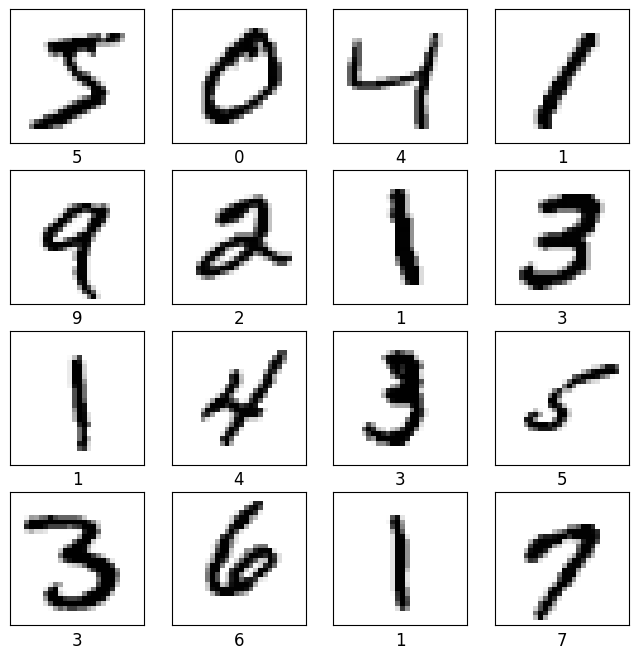

In [6]:
# Hiển thị dữ liệu train
plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([]), plt.yticks([]), plt.grid(False)
    plt.imshow(x_train[i], cmap=plt.cm.binary)
    plt.xlabel(f'{y_train[i]}', fontsize = 12)
plt.show()

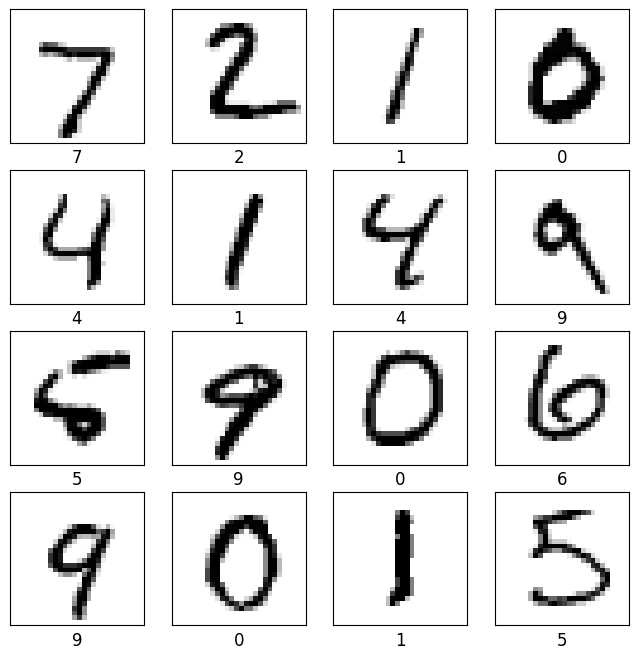

In [7]:
# Hiển thị dữ liệu test
plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([]), plt.yticks([]), plt.grid(False)
    plt.imshow(x_test[i], cmap=plt.cm.binary)
    plt.xlabel(f'{y_test[i]}', fontsize = 12)
plt.show()

## 4. Tiền xử lý dữ liệu

In [8]:
# Biến đổi ảnh về miền trị [0,1]
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

In [9]:
# Mở rộng shape tại chiều cuối cùng (n_images,28,28) --> (n_images, 28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

In [10]:
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")

x_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


In [11]:
# Chuyển đổi y_train, y_test sang dạng one-hot
num_classes = 10 # phân lớp 10 ký tự số (từ 0 đến 9)
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

In [12]:
# dạng one-hot
y_train[0:10]

array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]])

In [13]:
# dùng np.argmax để tìm vị trí có giá trị xác suất lớn nhất (đưa về label)
np.argmax(y_train[0:10], axis = 1)

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4])

## 5. Xây dựng Model

In [14]:
# xóa các lưu trữ
keras.backend.clear_session()

# xây dựng model
input_shape = (28, 28, 1)

# input
input_ = keras.Input(shape=input_shape)

# các blocks convolution để lấy features
# block 1 (conv2d + activation + maxpool)
x = keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu")(input_)
x = keras.layers.MaxPooling2D(pool_size=(2, 2))(x)
# block 2 (conv2d + activation + maxpool)
x = keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu")(x)
x = keras.layers.MaxPooling2D(pool_size=(2, 2))(x)

# classification layers (gồm các dense layer, dropout)
x = keras.layers.Flatten()(x) # Đưa shape của x về dạng phẳng. Ví dụ: (28, 28, 1) --> (28x28x1, )
x = keras.layers.Dropout(0.5)(x) # Loại ngẫu nhiên 50% kết nối trong quá trình huấn luyện - tăng tính tổng quát hóa
output_ = keras.layers.Dense(num_classes, activation="softmax")(x) # kết xuất ra 10 classes dữ liệu dạng xác suất

model = keras.Model(inputs=input_, outputs=output_) # đưa vào model

model.summary() # hiển thị thông tin model

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Huấn luyện Model (Thí nghiệm mới: LR=0.001 (0.01), Batch=64 (128))

In [15]:
# khai báo learning rate, loss function, và model metric
model.compile(loss='categorical_crossentropy',
              optimizer=keras.optimizers.Adam(learning_rate=0.001), # (0.01)
              metrics=["accuracy"])

batch_size = 64 # (128)
epochs     = 20 # (15)

starting_time = time.time()
model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)
print('> training time is %.4f minutes' % ((time.time() - starting_time)/60))

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.9120 - loss: 0.2852 - val_accuracy: 0.9775 - val_loss: 0.0771
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9685 - loss: 0.1017 - val_accuracy: 0.9853 - val_loss: 0.0525
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9743 - loss: 0.0799 - val_accuracy: 0.9872 - val_loss: 0.0455
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9791 - loss: 0.0663 - val_accuracy: 0.9873 - val_loss: 0.0405
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9818 - loss: 0.0579 - val_accuracy: 0.9898 - val_loss: 0.0378
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9836 - loss: 0.0518 - val_accuracy: 0.9907 - val_loss: 0.0364
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9849 - loss: 0.0483 - val_accuracy: 0.9902 - val_loss: 0.0332
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9856 - loss: 0.0458 - 

In [16]:
# list all data in history
print(model.history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


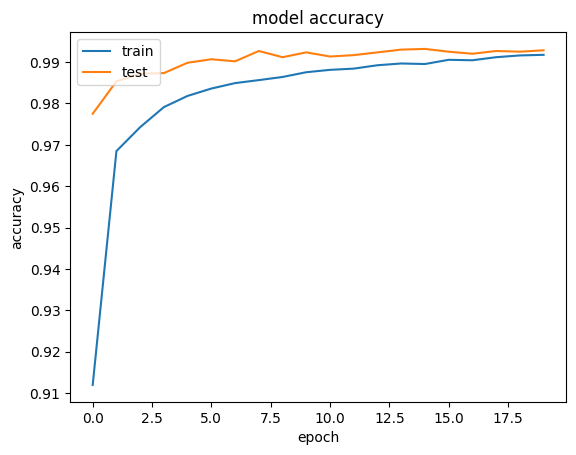

In [17]:
# summarize history for accuracy
plt.plot(model.history.history['accuracy'])
plt.plot(model.history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

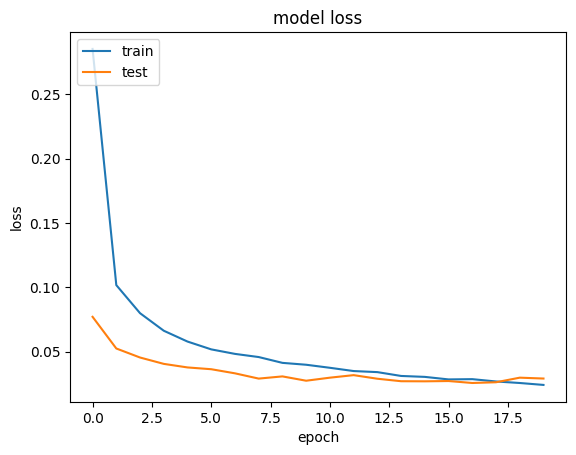

In [18]:
# summarize history for loss
plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

## 7. Lượng giá Model

In [19]:
score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 0.02298043482005596
Test accuracy: 0.9927999973297119


In [20]:
y_pred = model.predict(x_test)
y_pred_label = np.argmax(y_pred, axis = 1)
y_gt_label = np.argmax(y_test, axis = 1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [21]:
# Các vị trí bị sai
false_pos = np.where(y_pred_label != y_gt_label)[0]
print(f'False Cases: {len(false_pos)} / {len(y_gt_label)}\n{false_pos}')

False Cases: 72 / 10000
[ 321  445  659  684  947 1014 1039 1112 1182 1226 1232 1242 1247 1260
 1393 1530 1709 1878 1901 2035 2043 2053 2070 2130 2135 2182 2462 2597
 2654 2742 2896 2927 2939 2995 3073 3225 3289 3422 3520 3727 3767 3778
 3808 3853 3906 3941 4176 4205 4284 4360 4536 4571 4740 4761 5937 5955
 6560 6576 6597 6625 6651 6783 8408 9009 9015 9664 9679 9692 9698 9729
 9839 9904]


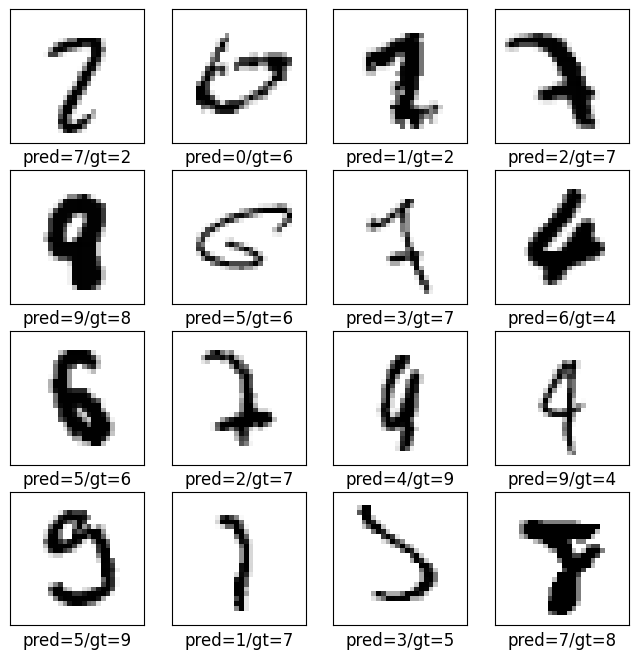

In [22]:
# Hiển thị dữ liệu test
plt.figure(figsize=(8, 8))
for i in range(16):
    pos = false_pos[i]
    plt.subplot(4,4,i+1)
    plt.xticks([]), plt.yticks([]), plt.grid(False)
    plt.imshow(x_test[pos], cmap=plt.cm.binary)
    plt.xlabel(f'pred={y_pred_label[pos]}/gt={y_gt_label[pos]}', fontsize = 12)
plt.show()

# Kết thúc